In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [15]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

In [16]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77946 entries, 0 to 77945
Data columns (total 28 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        77946 non-null  int64  
 1   tweet     77946 non-null  object 
 2   state     77946 non-null  object 
 3   location  66994 non-null  object 
 4   s1        77946 non-null  float64
 5   s2        77946 non-null  float64
 6   s3        77946 non-null  float64
 7   s4        77946 non-null  float64
 8   s5        77946 non-null  float64
 9   w1        77946 non-null  float64
 10  w2        77946 non-null  float64
 11  w3        77946 non-null  float64
 12  w4        77946 non-null  float64
 13  k1        77946 non-null  float64
 14  k2        77946 non-null  float64
 15  k3        77946 non-null  float64
 16  k4        77946 non-null  float64
 17  k5        77946 non-null  float64
 18  k6        77946 non-null  float64
 19  k7        77946 non-null  float64
 20  k8        77946 non-null  fl

In [17]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42157 entries, 0 to 42156
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   id        42157 non-null  int64 
 1   tweet     42157 non-null  object
 2   state     14323 non-null  object
 3   location  42144 non-null  object
dtypes: int64(1), object(3)
memory usage: 1.3+ MB


In [18]:
train.head()

,id,tweet,state,location,s1,s2,s3,s4,s5,w1,...,k6,k7,k8,k9,k10,k11,k12,k13,k14,k15
0,1,Jazz for a Rainy Afternoon: {link},oklahoma,Oklahoma,0.0,0.0,1.0,0.000,0.000,0.800,...,0.0,0.000,0.0,0.000,1.0,0.0,0.0,0.000,0.0,0.0
1,2,RT: @mention: I love rainy days.,florida,Miami-Ft. Lauderdale,0.0,0.0,0.0,1.000,0.000,0.196,...,0.0,0.000,0.0,0.000,1.0,0.0,0.0,0.000,0.0,0.0
2,3,Good Morning Chicago! Time to kick the Windy C...,idaho,NaN,0.0,0.0,0.0,0.000,1.000,0.000,...,0.0,1.000,0.0,0.000,0.0,0.0,0.0,0.000,0.0,0.0
3,6,Preach lol! :) RT @mention: #alliwantis this t...,minnesota,Minneapolis-St. Paul,0.0,0.0,0.0,1.000,0.000,1.000,...,0.0,0.604,0.0,0.196,0.0,0.0,0.0,0.201,0.0,0.0
4,9,@mention good morning sunshine,rhode island,Purgatory,0.0,0.0,0.0,0.403,0.597,1.000,...,0.0,0.000,0.0,0.000,0.0,0.0,0.0,1.000,0.0,0.0


In [19]:
print(f"Train shape: {train.shape}")
print(f"Test shape: {test.shape}")

Train shape: (77946, 28)
Test shape: (42157, 4)


In [20]:
# Procentowy udział braków danych
print(" Missing values in the training set (%)")
print((train.isnull().sum() / len(train) * 100).round(2).loc[lambda x: x > 0])

print("\n Missing values in the test set (%)")
print((test.isnull().sum() / len(test) * 100).round(2).loc[lambda x: x > 0])

 Missing values in the training set (%)
location    14.05
dtype: float64

 Missing values in the test set (%)
state       66.02
location     0.03
dtype: float64


In [21]:
import re

# deleting unnecessary columns
train_clean = train.drop(columns=['state', 'location'])
test_clean = test.drop(columns=['state', 'location'])

# text cleaning function
def clean_tweet(text):
    if not isinstance(text, str):
        return ""
    
    text = text.lower()
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE) # url removal
    text = re.sub(r'\@\w+', '', text) # @mentions removal
    
    # hashtag removal, but keeping the text
    text = text.replace('#', '') 
    
    # special character removal
    text = re.sub(r'[^\w\s]', '', text) 
    
    # multiple spaces removal
    text = re.sub(r'\s+', ' ', text).strip()
    
    return text

train_clean['cleaned_tweet'] = train_clean['tweet'].apply(clean_tweet)
test_clean['cleaned_tweet'] = test_clean['tweet'].apply(clean_tweet)



print("Before cleaning:")
print(train_clean['tweet'].head(3).values)
print("\nAfter cleaning:")
print(train_clean['cleaned_tweet'].head(3).values)

Before cleaning:
['Jazz for a Rainy Afternoon:  {link}' 'RT: @mention: I love rainy days.'
 'Good Morning Chicago! Time to kick the Windy City in the nuts and head back West!']

After cleaning:
['jazz for a rainy afternoon link' 'rt i love rainy days'
 'good morning chicago time to kick the windy city in the nuts and head back west']


In [25]:
train_clean.to_csv('train_clean.csv', index=False)
test_clean.to_csv('test_clean.csv', index=False)

In [22]:
# grouping columns
s_cols = [f's{i}' for i in range(1, 6)]
w_cols = [f'w{i}' for i in range(1, 5)]
k_cols = [f'k{i}' for i in range(1, 16)]

# stats
train['s_sum'] = train[s_cols].sum(axis=1)
train['w_sum'] = train[w_cols].sum(axis=1)

print("s1-s5:")
print(train['s_sum'].describe())

print("\nw1-w4:")
print(train['w_sum'].describe())

s1-s5:
count    77946.000000
mean         1.000001
std          0.000275
min          0.999000
25%          1.000000
50%          1.000000
75%          1.000000
max          1.002000
Name: s_sum, dtype: float64

w1-w4:
count    77946.000000
mean         1.000000
std          0.000135
min          0.999000
25%          1.000000
50%          1.000000
75%          1.000000
max          1.001000
Name: w_sum, dtype: float64


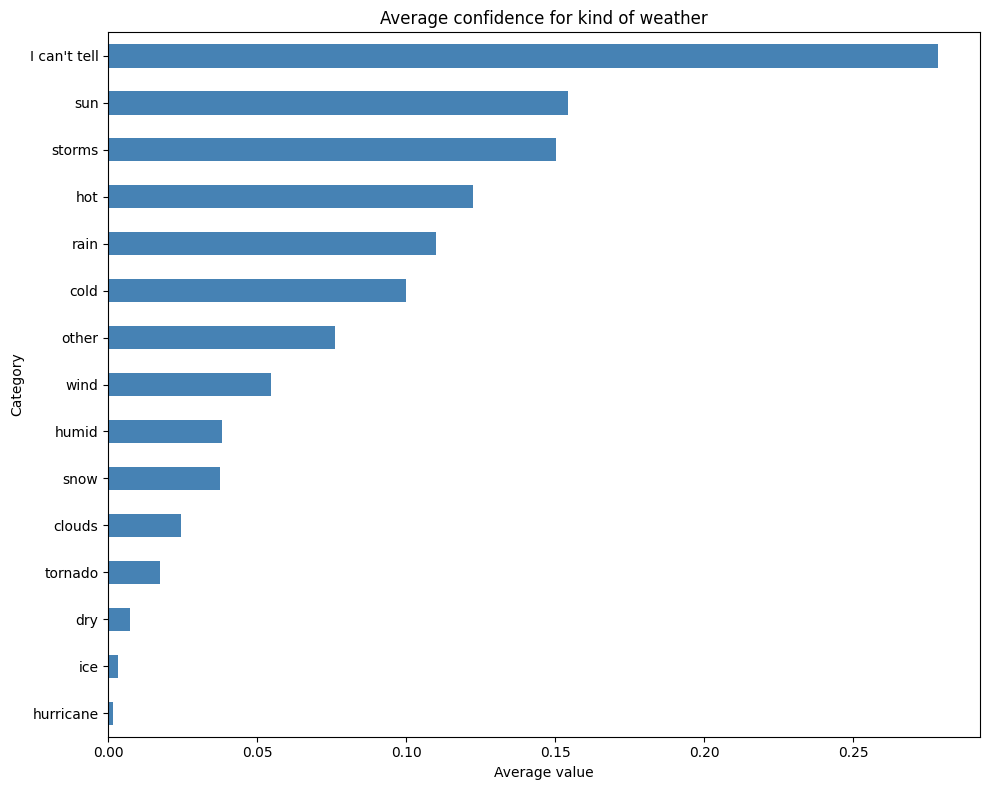

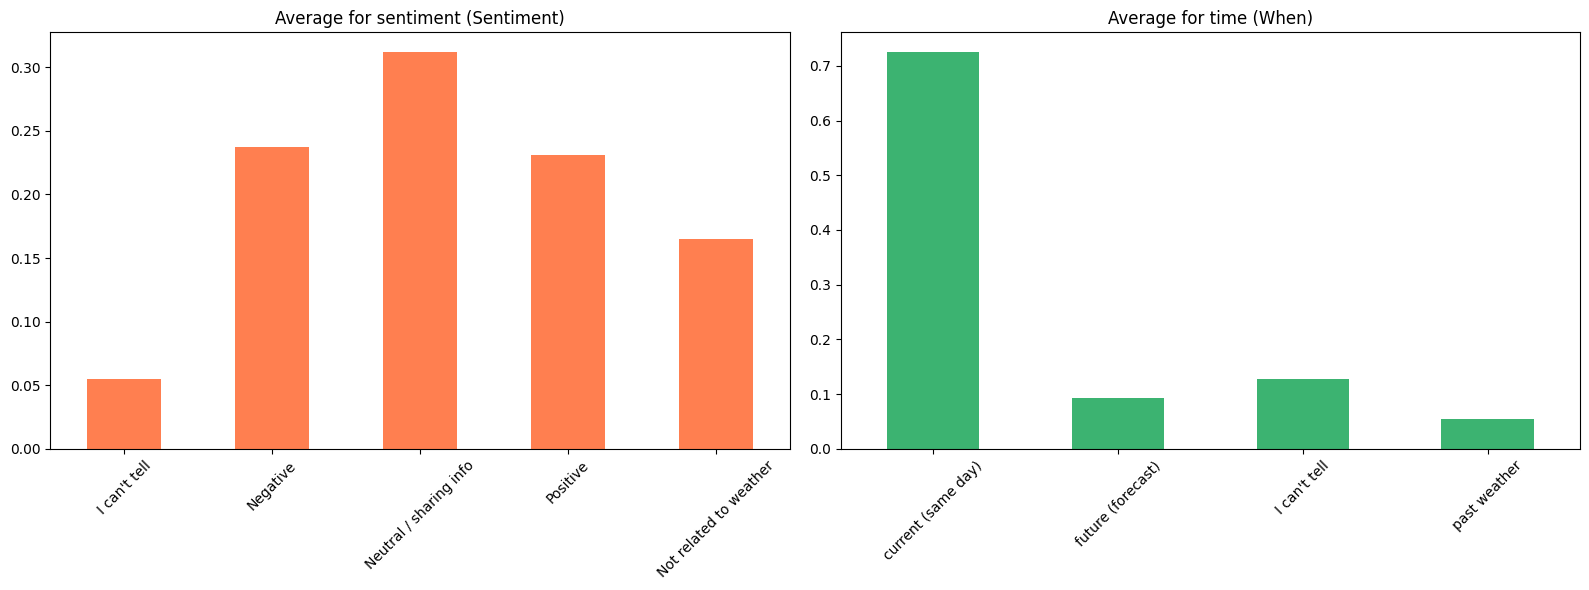

In [23]:
# mapping for better readability
s_mapping = {
    's1': "I can't tell",
    's2': "Negative",
    's3': "Neutral / sharing info",
    's4': "Positive",
    's5': "Not related to weather"
}

w_mapping = {
    'w1': "current (same day)",
    'w2': "future (forecast)",
    'w3': "I can't tell",
    'w4': "past weather"
}

k_mapping = {
    'k1': "clouds", 'k2': "cold", 'k3': "dry", 'k4': "hot",
    'k5': "humid", 'k6': "hurricane", 'k7': "I can't tell",
    'k8': "ice", 'k9': "other", 'k10': "rain", 'k11': "snow",
    'k12': "storms", 'k13': "sun", 'k14': "tornado", 'k15': "wind"
}

# means
k_means = train[k_cols].mean().rename(index=k_mapping).sort_values()
s_means = train[s_cols].mean().rename(index=s_mapping)
w_means = train[w_cols].mean().rename(index=w_mapping)

# target distribution
plt.figure(figsize=(10, 8))
k_means.plot(kind='barh', color='steelblue')
plt.title('Average confidence for kind of weather')
plt.xlabel('Average value')
plt.ylabel('Category')
plt.tight_layout()
plt.show()

# time sentiment
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

s_means.plot(kind='bar', ax=axes[0], color='coral')
axes[0].set_title('Average for sentiment (Sentiment)')
axes[0].tick_params(axis='x', rotation=45)

w_means.plot(kind='bar', ax=axes[1], color='mediumseagreen')
axes[1].set_title('Average for time (When)')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

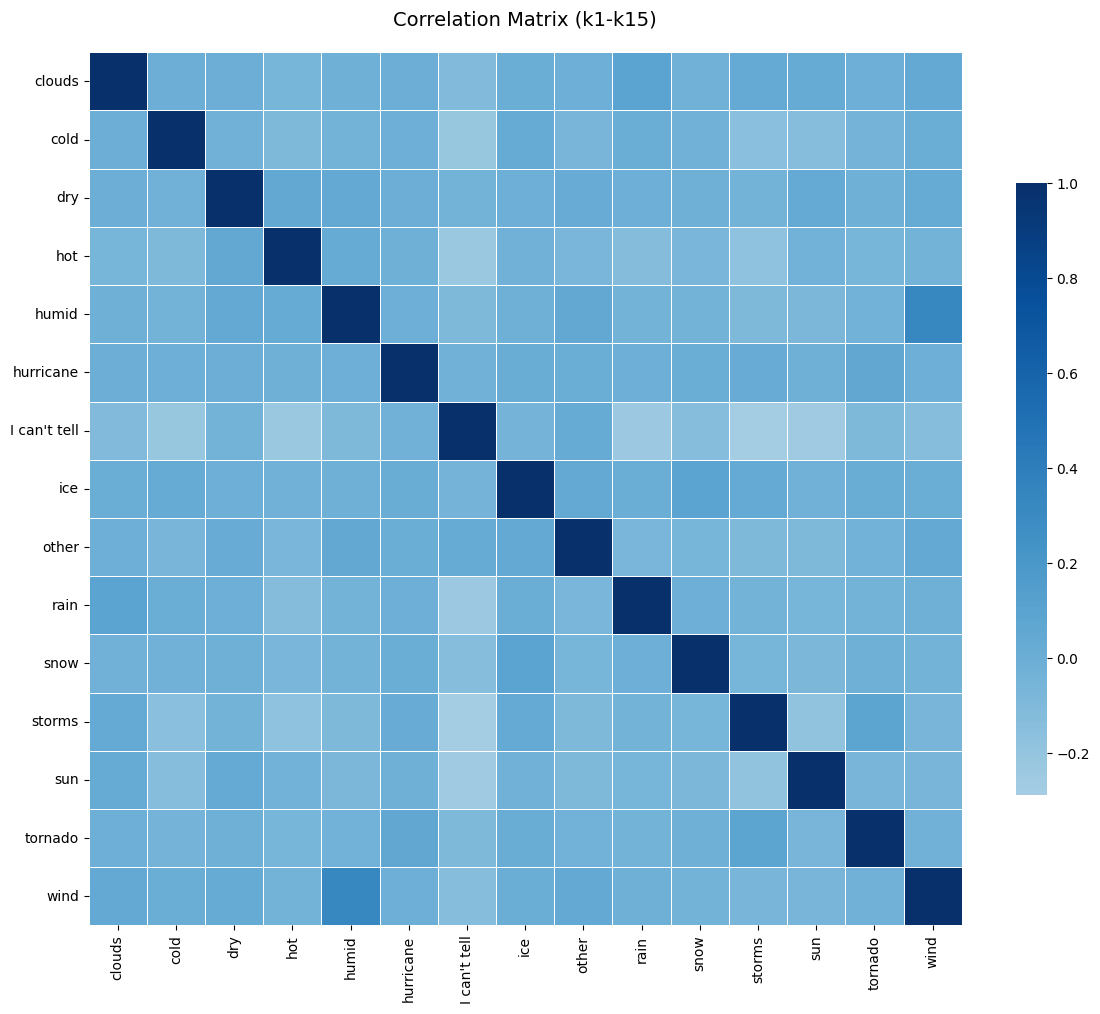

In [26]:
# corr matrix (k1-k15)
plt.figure(figsize=(12, 10))
corr_matrix = train_clean[k_cols].corr()

corr_matrix.columns = [k_mapping[col] for col in corr_matrix.columns]
corr_matrix.index = [k_mapping[idx] for idx in corr_matrix.index]

sns.heatmap(corr_matrix, annot=False, cmap='Blues', center=0, 
            square=True, linewidths=.5, cbar_kws={"shrink": .7})
plt.title('Correlation Matrix (k1-k15)', pad=20, fontsize=14)
plt.tight_layout()
plt.show()

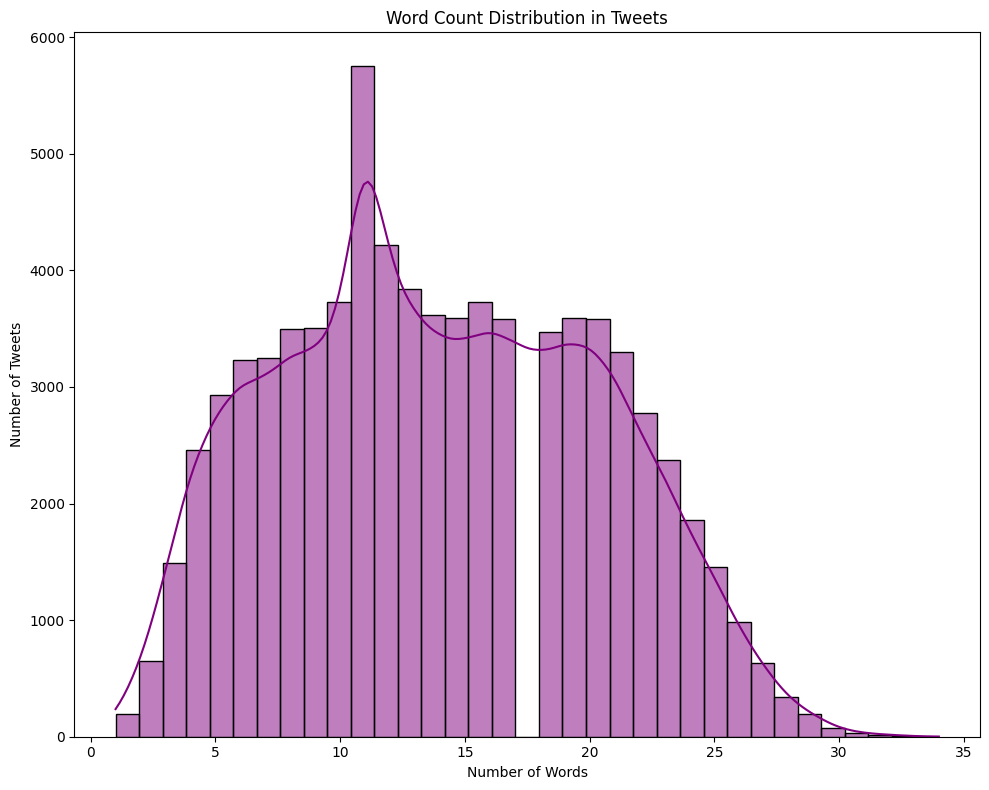

C:\Users\kinga\AppData\Local\Temp\ipykernel_8012\3940933211.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=train_clean, x='length_bin', y='s1', palette='viridis')


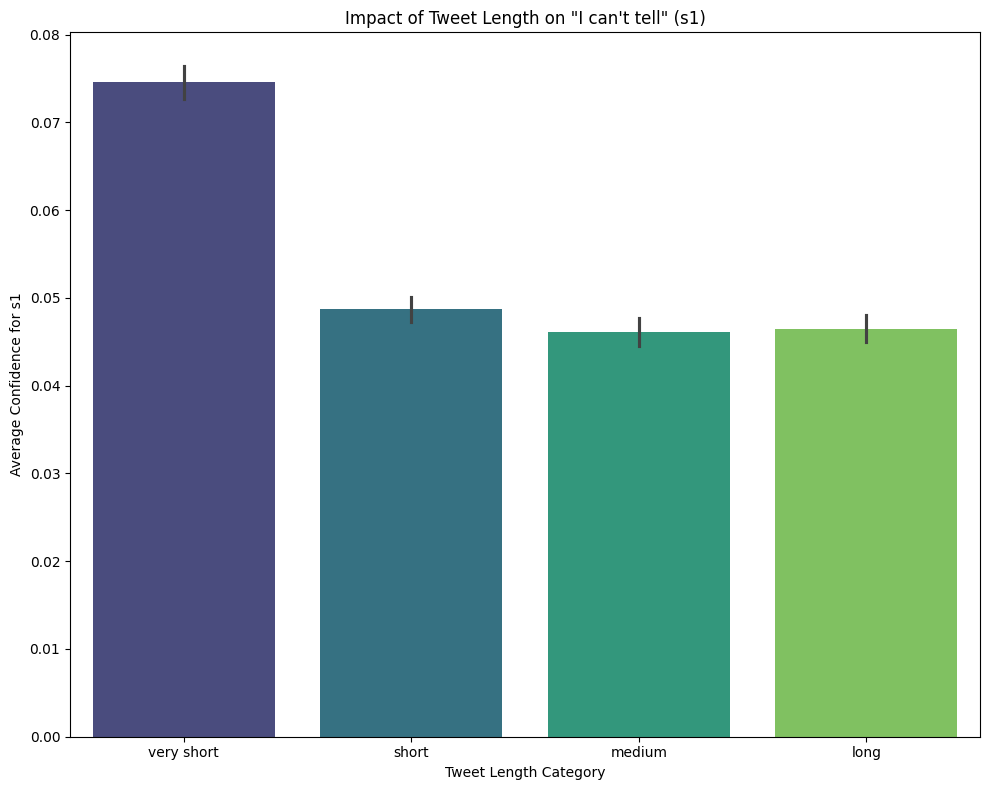

In [30]:
# word count distribution and its impact on "I can't tell" (s1)
train_clean['word_count'] = train_clean['cleaned_tweet'].apply(lambda x: len(str(x).split()))



plt.figure(figsize=(10, 8))

sns.histplot(data=train_clean, x='word_count', bins=35, kde=True, color='purple')
plt.title('Word Count Distribution in Tweets')
plt.xlabel('Number of Words')
plt.ylabel('Number of Tweets')
plt.tight_layout()
plt.show()

train_clean['length_bin'] = pd.qcut(train_clean['word_count'], q=4, labels=['very short', 'short', 'medium', 'long'])
plt.figure(figsize=(10, 8))
sns.barplot(data=train_clean, x='length_bin', y='s1', palette='viridis')
plt.title('Impact of Tweet Length on "I can\'t tell" (s1)')
plt.xlabel('Tweet Length Category')
plt.ylabel('Average Confidence for s1')

plt.tight_layout()
plt.show()

C:\Users\kinga\AppData\Local\Temp\ipykernel_8012\128641395.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_hashtags.values, y=top_hashtags.index, palette='viridis')


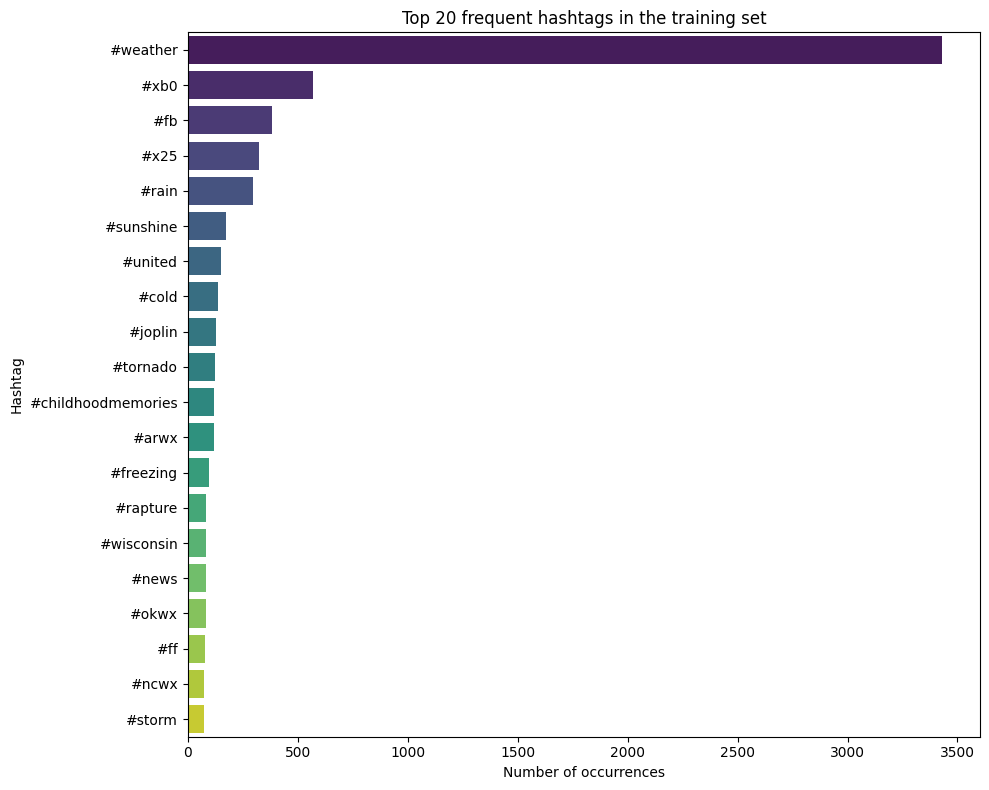

In [32]:
# hashtag analysis
hashtags = train['tweet'].str.findall(r'#\w+').explode().dropna().str.lower()

#top 20 hashtags
top_hashtags = hashtags.value_counts().head(20)

plt.figure(figsize=(10, 8))
sns.barplot(x=top_hashtags.values, y=top_hashtags.index, palette='viridis')
plt.title('Top 20 frequent hashtags in the training set')
plt.xlabel('Number of occurrences')
plt.ylabel('Hashtag')
plt.tight_layout()
plt.show()